# AIE 425 – Intelligent Recommender Systems
## Lab 3: Synthetic Rating Matrices

**Completed notebook solution**

This notebook covers the three samplers, rating matrix generation, CSV interaction logs, sparsity and homogeneity metrics, plots, missing-data experiments, cold-start simulation, and discussion answers. Run all cells from top to bottom to reproduce the results and regenerate the CSV files.

## Part 1 – Imports and reproducibility
The lab requires `random.random()` as the source of randomness for the samplers. `random.sample()` is used to select distinct items. NumPy is used only for storage/statistics and Matplotlib for plots.

In [1]:
import random
import math
import csv
import statistics
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

random.seed(425)
RATING_MIN, RATING_MAX = 1, 5
N_USERS, N_ITEMS = 5000, 100
DISTRIBUTIONS = ["uniform", "normal", "poisson"]


## Part 2 – Build the three samplers
- Uniform: scale a random number from `[0, 1)` to `[a, b)`.
- Normal: use the Box–Muller transform.
- Poisson: use Knuth’s algorithm.

In [2]:
def sample_uniform(a, b):
    u = random.random()
    return a + (b - a) * u

def sample_normal(mu, sigma):
    # Box–Muller transform; 1 - random.random() avoids log(0)
    u1 = 1 - random.random()
    u2 = random.random()
    z = math.sqrt(-2 * math.log(u1)) * math.cos(2 * math.pi * u2)
    return mu + sigma * z

def sample_poisson(lam):
    # Knuth's algorithm
    L = math.exp(-lam)
    k = 0
    p = 1.0
    while True:
        p *= random.random()
        if p <= L:
            return k
        k += 1

# Check the sample means and variances using 100,000 samples.
def sample_variance(values):
    mean = sum(values) / len(values)
    return sum((x - mean) ** 2 for x in values) / len(values)

sampler_results = {}
for name, sampler in [
    ("uniform", lambda: sample_uniform(0, 1)),
    ("normal", lambda: sample_normal(3, 1)),
    ("poisson", lambda: sample_poisson(2))
]:
    values = [sampler() for _ in range(100_000)]
    sampler_results[name] = {
        "sample_mean": sum(values) / len(values),
        "sample_variance": sample_variance(values)
    }

sampler_results


{'uniform': {'sample_mean': 0.49879233169492326,
  'sample_variance': 0.08309715440419806},
 'normal': {'sample_mean': 2.996357089167957,
  'sample_variance': 1.002903621414598},
 'poisson': {'sample_mean': 1.999, 'sample_variance': 2.0006589999999997}}

**Question (uniform rating range):** Why use `[0.5, 5.5)` rather than `[1, 5]`?  
Because we round each raw value to the nearest integer. Values in `[0.5, 1.5)` round to 1, `[1.5, 2.5)` round to 2, and so on, giving approximately equal chances for ratings 1–5.

**Why add 1 to the Poisson sample?**  
A Poisson sample can be 0 or higher. Adding 1 shifts it to 1–6, and clipping to 5 gives a valid rating scale from 1 to 5.

## Part 3 – Required functions and datasets
`generate_ratings` rounds and clips ratings to 1–5. `assign_ratings` leaves at least half of each user's items missing and uses `None` for missing ratings.

In [3]:
def clip_rating(x):
    return max(1, min(5, int(round(x))))

def generate_ratings(n, dist, **params):
    ratings = []
    for _ in range(n):
        if dist == "uniform":
            raw = sample_uniform(0.5, 5.5)
        elif dist == "normal":
            mu = params.get("mu", 3)
            sigma = params.get("sigma", 1)
            raw = sample_normal(mu, sigma)
        elif dist == "poisson":
            lam = params.get("lam", 2)
            raw = 1 + sample_poisson(lam)
        else:
            raise ValueError("Unknown distribution: " + str(dist))
        ratings.append(clip_rating(raw))
    return ratings

def assign_ratings(n_items, dist, max_fill=0.5, **params):
    row = [None] * n_items
    max_rated = int(max_fill * n_items)
    k = random.randint(5, max_rated)
    chosen_items = random.sample(range(n_items), k)
    ratings = generate_ratings(k, dist, **params)
    for item_idx, rating in zip(chosen_items, ratings):
        row[item_idx] = rating
    assert row.count(None) >= n_items * 0.5, "At least 50% of ratings must be missing"
    return row

def build_matrix(n_users, n_items, dist, **params):
    matrix = [assign_ratings(n_items, dist, **params) for _ in range(n_users)]
    # Check the 50% missing rule for every user
    assert all(row.count(None) >= n_items * 0.5 for row in matrix)
    return matrix

# Build all three matrices. The seed was set once at the top.
matrices = {}
for dist in DISTRIBUTIONS:
    matrices[dist] = build_matrix(N_USERS, N_ITEMS, dist)

print("Matrix sizes:")
for dist, matrix in matrices.items():
    print(dist, len(matrix), "users ×", len(matrix[0]), "items")


Matrix sizes:
uniform 5000 users × 100 items
normal 5000 users × 100 items
poisson 5000 users × 100 items


### Save the three matrices as interaction-log CSV files
Each line represents one observed user–item rating: `user_id,item_id,rating`. Missing ratings are not written to the CSV.

In [4]:
def save_interactions_csv(matrix, filename):
    with open(filename, "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["user_id", "item_id", "rating"])
        for user_idx, row in enumerate(matrix):
            for item_idx, rating in enumerate(row):
                if rating is not None:
                    writer.writerow([user_idx, item_idx, rating])

for dist, matrix in matrices.items():
    save_interactions_csv(matrix, f"{dist}_ratings.csv")

print("Saved uniform_ratings.csv, normal_ratings.csv, and poisson_ratings.csv")


Saved uniform_ratings.csv, normal_ratings.csv, and poisson_ratings.csv


## Part 4 – Sparsity, means, and homogeneity
The global mean counts each observed rating once. The mean of user means counts each user once. These can differ when users have different numbers of ratings.

In [5]:
def observed_values(matrix):
    return [rating for row in matrix for rating in row if rating is not None]

def user_means(matrix):
    means = []
    for row in matrix:
        values = [x for x in row if x is not None]
        if values:
            means.append(sum(values) / len(values))
    return means

def item_means(matrix):
    n_items = len(matrix[0])
    means = []
    for j in range(n_items):
        values = [row[j] for row in matrix if row[j] is not None]
        means.append(sum(values) / len(values) if values else float("nan"))
    return means

def sparsity(matrix):
    total = len(matrix) * len(matrix[0])
    observed = sum(x is not None for row in matrix for x in row)
    return 1 - observed / total

def normalized_entropy(matrix):
    values = observed_values(matrix)
    counts = Counter(values)
    n = len(values)
    entropy = 0.0
    for rating in range(1, 6):
        p = counts[rating] / n
        if p > 0:
            entropy -= p * math.log(p)
    return entropy / math.log(5)

def chi_square_uniform(matrix):
    values = observed_values(matrix)
    counts = Counter(values)
    n = len(values)
    expected = n / 5
    return sum((counts[v] - expected) ** 2 / expected for v in range(1, 6))

def gini(values):
    xs = sorted(float(x) for x in values)
    n = len(xs)
    total = sum(xs)
    if n == 0 or total == 0:
        return 0.0
    return sum((2 * (i + 1) - n - 1) * x for i, x in enumerate(xs)) / (n * total)

def homogeneity_metrics(matrix):
    values = observed_values(matrix)
    ums = user_means(matrix)
    ims = [x for x in item_means(matrix) if not math.isnan(x)]
    counts = Counter(values)
    n = len(values)
    histogram = {v: 100 * counts[v] / n for v in range(1, 6)}
    item_popularity = [sum(row[j] is not None for row in matrix) for j in range(len(matrix[0]))]
    row_fill = [sum(x is not None for x in row) / len(row) for row in matrix]
    return {
        "Sparsity": sparsity(matrix),
        "Global mean": sum(values) / len(values),
        "Mean of user means": sum(ums) / len(ums),
        "Smallest user mean": min(ums),
        "Largest user mean": max(ums),
        "Normalized entropy": normalized_entropy(matrix),
        "Chi-square vs uniform": chi_square_uniform(matrix),
        "Std of user means": statistics.pstdev(ums),
        "Std of item means": statistics.pstdev(ims),
        "Gini of item popularity": gini(item_popularity),
        "Max row fill (%)": 100 * max(row_fill),
        "Rating histogram (%)": histogram
    }

metrics = {dist: homogeneity_metrics(matrix) for dist, matrix in matrices.items()}

# Main comparison table (rounded for readability).
metric_columns = [
    "Sparsity", "Global mean", "Mean of user means", "Smallest user mean",
    "Largest user mean", "Normalized entropy", "Chi-square vs uniform",
    "Std of user means", "Std of item means", "Gini of item popularity", "Max row fill (%)"
]
comparison = pd.DataFrame({dist: {k: v for k, v in result.items() if k in metric_columns}
                           for dist, result in metrics.items()}).T[metric_columns]
display(comparison.round(4))

histogram_table = pd.DataFrame({dist: result["Rating histogram (%)"] for dist, result in metrics.items()}).T
histogram_table.columns = [f"Rating {i} (%)" for i in range(1, 6)]
print("Rating distribution (% of observed ratings):")
display(histogram_table.round(2))

,Sparsity,Global mean,Mean of user means,Smallest user mean,Largest user mean,Normalized entropy,Chi-square vs uniform,Std of user means,Std of item means,Gini of item popularity,Max row fill (%)
uniform,0.7276,2.9987,2.9980,1.3750,4.6000,1.0000,1.1895,0.3259,0.0372,0.0123,50.0
normal,0.7243,2.9963,2.9946,1.7143,4.4286,0.8813,49135.3083,0.2359,0.0277,0.0122,50.0
poisson,0.7252,2.9266,2.9257,1.4000,4.4000,0.9720,12454.0633,0.2853,0.0361,0.0124,50.0


Rating distribution (% of observed ratings):


,Rating 1 (%),Rating 2 (%),Rating 3 (%),Rating 4 (%),Rating 5 (%)
uniform,20.01,20.02,19.96,20.09,19.92
normal,6.84,24.22,38.04,24.25,6.65
poisson,13.49,26.88,27.40,17.92,14.30


### Mini example (by hand)
- User A rated 8 items, all with 5: user mean = 5.
- User B rated 2 items, both with 1: user mean = 1.
- Global mean = `(8×5 + 2×1) / 10 = 4.2`.
- Mean of user means = `(5 + 1) / 2 = 3.0`.

The global mean is weighted by the number of ratings, while the mean of user means gives each user equal weight.

### Rating histograms and heatmaps
Missing values are displayed as white in the heatmaps.

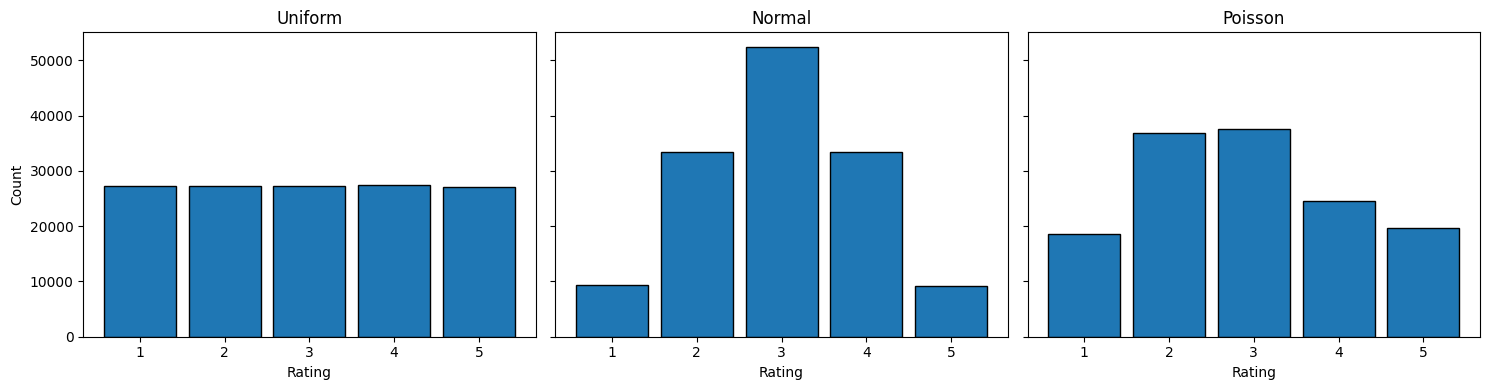

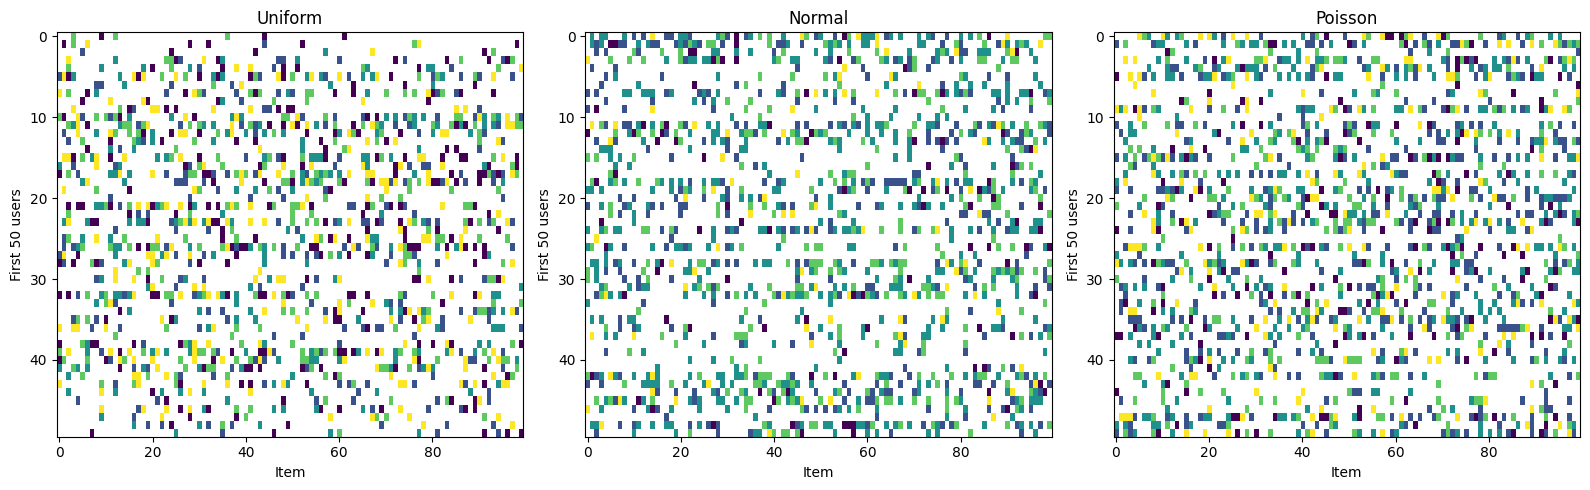

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, dist in zip(axes, DISTRIBUTIONS):
    vals = observed_values(matrices[dist])
    ax.hist(vals, bins=np.arange(0.5, 6.5, 1), edgecolor="black", rwidth=0.85)
    ax.set_title(dist.capitalize())
    ax.set_xlabel("Rating")
    ax.set_xticks([1, 2, 3, 4, 5])
axes[0].set_ylabel("Count")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, dist in zip(axes, DISTRIBUTIONS):
    arr = np.array([[np.nan if x is None else x for x in row] for row in matrices[dist][:50]], dtype=float)
    cmap = plt.cm.viridis.copy()
    cmap.set_bad(color="white")
    ax.imshow(np.ma.masked_invalid(arr), aspect="auto", interpolation="nearest", cmap=cmap, vmin=1, vmax=5)
    ax.set_title(dist.capitalize())
    ax.set_xlabel("Item")
    ax.set_ylabel("First 50 users")
plt.tight_layout()
plt.show()


## Part 5 – Missing-data experiment: bias or noise?
We create a complete normal-rating matrix and keep its true means as references. For each hiding percentage, we repeat the hiding process 20 times.

- `random`: each cell has an equal chance of being hidden.
- `dislike`: the lab's specified rule is `key = random.random() / rating`, and the largest keys are kept. Taken literally, this tends to keep lower ratings more often and can bias the observed mean downward. This is opposite to the prose description that users skip disliked (low-rated) items; the implementation follows the stated formula.

In [7]:
def complete_matrix(n_users, n_items, dist, **params):
    return [generate_ratings(n_items, dist, **params) for _ in range(n_users)]

def mean_of_user_means_nonempty(matrix):
    means = []
    for row in matrix:
        vals = [x for x in row if x is not None]
        if vals:
            means.append(sum(vals) / len(vals))
    return sum(means) / len(means) if means else float("nan")

def hide_ratings(full, p, mechanism):
    n_users = len(full)
    n_items = len(full[0])
    total = n_users * n_items
    n_keep = int(round((1 - p) * total))
    candidates = []
    for u, row in enumerate(full):
        for i, rating in enumerate(row):
            if mechanism == "random":
                key = random.random()
            elif mechanism == "dislike":
                # Follow the lab formula literally: key = random.random() / rating.
                # Keeping the largest keys tends to retain lower ratings more often.
                key = random.random() / rating
            else:
                raise ValueError("Unknown mechanism")
            candidates.append((key, u, i))
    candidates.sort(reverse=True)
    keep = {(u, i) for _, u, i in candidates[:n_keep]}
    hidden = []
    for u, row in enumerate(full):
        hidden.append([rating if (u, i) in keep else None for i, rating in enumerate(row)])
    return hidden

def matrix_global_mean(matrix):
    vals = observed_values(matrix)
    return sum(vals) / len(vals) if vals else float("nan")

# Full 5000 × 100 normal matrix; reference means are computed before hiding.
full_normal = complete_matrix(N_USERS, N_ITEMS, "normal", mu=3, sigma=1)
reference_global = matrix_global_mean(full_normal)
reference_user_means = sum(sum(row) / len(row) for row in full_normal) / len(full_normal)

print("Reference global mean:", reference_global)
print("Reference mean of user means:", reference_user_means)


Reference global mean: 2.999278
Reference mean of user means: 2.999278


In [17]:
def run_missing_experiment(full, reference_global, reference_user_means, trials=20):
    results = []
    for mechanism in ["random", "dislike"]:
        for p in [0.50, 0.75, 0.90]:
            errors_global = []
            errors_user = []
            for _ in range(trials):
                hidden = hide_ratings(full, p, mechanism)
                errors_global.append(matrix_global_mean(hidden) - reference_global)
                errors_user.append(mean_of_user_means_nonempty(hidden) - reference_user_means)
            results.append({
                "Mechanism": mechanism,
                "Hidden": f"{int(p*100)}%",
                "Bias of global mean": sum(errors_global) / len(errors_global),
                "Random error of global mean": statistics.pstdev(errors_global),
                "Bias of mean user means": sum(errors_user) / len(errors_user),
                "Random error of mean user means": statistics.pstdev(errors_user)
            })
    return results

missing_results = run_missing_experiment(full_normal, reference_global, reference_user_means, trials=20)
for row in missing_results:
    print(row)


{'Mechanism': 'random', 'Hidden': '50%', 'Bias of global mean': -0.0002625999999999129, 'Random error of global mean': 0.0013206018476437024, 'Bias of mean user means': -0.0003042978594725021, 'Random error of mean user means': 0.0013254248655194861}
{'Mechanism': 'random', 'Hidden': '75%', 'Bias of global mean': -0.0005499999999999172, 'Random error of global mean': 0.002460879842657885, 'Bias of mean user means': -0.0008181376765190818, 'Random error of mean user means': 0.002410556574827598}
{'Mechanism': 'random', 'Hidden': '90%', 'Bias of global mean': 0.00073500000000013, 'Random error of global mean': 0.004010702058243682, 'Bias of mean user means': 0.0008136303910351473, 'Random error of mean user means': 0.004596576477185375}
{'Mechanism': 'dislike', 'Hidden': '50%', 'Bias of global mean': -0.3392799999999999, 'Random error of global mean': 0.001161467692189529, 'Bias of mean user means': -0.33932924998538494, 'Random error of mean user means': 0.0011562820846818913}
{'Mechani

## Part 6 – Simulate cold start
Add 10 new items with 0–2 ratings each, and 500 new users who rate only 1–3 randomly chosen old items. The original matrix is not modified.

In [18]:
def add_cold_start(matrix, dist):
    old_matrix = [row[:] for row in matrix]
    old_users = len(old_matrix)
    old_items = len(old_matrix[0])
    new_items = 10
    new_users = 500
    expanded = [row + [None] * new_items for row in old_matrix]

    # Each new item receives 0–2 ratings from randomly selected existing users.
    for j in range(old_items, old_items + new_items):
        k = random.randint(0, 2)
        users = random.sample(range(old_users), k)
        item_ratings = generate_ratings(k, dist)
        for u, rating in zip(users, item_ratings):
            expanded[u][j] = rating

    # Each new user rates only 1–3 random old items.
    for _ in range(new_users):
        row = [None] * (old_items + new_items)
        k = random.randint(1, 3)
        chosen = random.sample(range(old_items), k)
        ratings = generate_ratings(k, dist)
        for i, rating in zip(chosen, ratings):
            row[i] = rating
        expanded.append(row)
    return expanded

def rated_item_sets(matrix):
    return [set(i for i, x in enumerate(row) if x is not None) for row in matrix]

def cold_start_metrics(before, after, old_user_count, old_item_count):
    after_sparsity = sparsity(after)
    cold_user_indices = range(old_user_count, len(after))
    cold_item_indices = range(old_item_count, len(after[0]))
    cold_users = [u for u in cold_user_indices if sum(x is not None for x in after[u]) < 5]
    cold_items = [
        i for i in cold_item_indices
        if sum(after[u][i] is not None for u in range(len(after))) < 5
    ]

    sets = rated_item_sets(after)
    cold_old_overlaps = []
    no_overlap = 0
    total_pairs = 0
    for cu in cold_user_indices:
        for ou in range(old_user_count):
            overlap = len(sets[cu] & sets[ou])
            cold_old_overlaps.append(overlap)
            no_overlap += (overlap == 0)
            total_pairs += 1

    # Use 1,000 random pairs of old users as the comparison requested in the lab.
    old_old_overlaps = []
    for _ in range(1000):
        u1, u2 = random.sample(range(old_user_count), 2)
        old_old_overlaps.append(len(sets[u1] & sets[u2]))

    return {
        "Sparsity before": sparsity(before),
        "Sparsity after": after_sparsity,
        "Cold users (<5 ratings)": len(cold_users),
        "Cold items (<5 ratings)": len(cold_items),
        "Mean co-rated items (cold vs old)": sum(cold_old_overlaps) / len(cold_old_overlaps),
        "Mean co-rated items (old vs old; 1000 pairs)": sum(old_old_overlaps) / len(old_old_overlaps),
        "No overlap among cold-old pairs (%)": 100 * no_overlap / total_pairs
    }

uniform_with_cold_start = add_cold_start(matrices["uniform"], "uniform")
cold_results = cold_start_metrics(
    matrices["uniform"], uniform_with_cold_start, N_USERS, N_ITEMS
)
cold_results


{'Sparsity before': 0.727584,
 'Sparsity after': 0.773196694214876,
 'Cold users (<5 ratings)': 500,
 'Cold items (<5 ratings)': 10,
 'Mean co-rated items (cold vs old)': 0.5434392,
 'Mean co-rated items (old vs old; 1000 pairs)': 7.415,
 'No overlap among cold-old pairs (%)': 56.36724}

## Part 7 – Discussion questions (student-style answers)
Use the actual values printed by your notebook where a question asks for numbers. The explanations below are based on the lab design; edit the bracketed parts after running the code.

## Part 7 – Discussion questions (answers based on the experiment)

**1. Which matrix spreads its ratings most evenly over 1–5?**  
The **uniform matrix** spreads ratings most evenly. Its rating percentages are approximately 20.01%, 20.02%, 19.96%, 20.09%, and 19.92% for ratings 1–5. Its normalized entropy is about **1.0000**, which is the maximum possible value.

**2. Is sparsity different between the three matrices? Why or why not?**  
The values are close but not exactly identical: uniform **72.76%**, normal **72.43%**, and Poisson **72.52%** in this run. The small differences come from random variation in the number of items assigned to each user; the rating distribution changes the rating values, while the random assignment process determines how many ratings are observed.

**3. In the normal matrix, which rating appears most often? Why?**  
Rating **3** appears most often (about **38.04%**) because the normal distribution is centered at μ = 3, so values near 3 are more likely before rounding and clipping.

**4. After cold start, how many co-rated items does a new user share with an old user on average? Can cosine similarity be computed with 0 co-rated items?**  
In this run, a cold user and an old user share about **0.5434 items on average**. If they have zero co-rated items, cosine similarity cannot be meaningfully calculated from their co-rated ratings because there are no shared values to compare.

**5. Netflix asks new users to pick a few titles they like. Which cold-start problem does that solve?**  
It mainly addresses the **new-user cold-start problem** by collecting initial preference information. It does not directly solve the new-item cold-start problem.

**6. Why may the global mean and the unweighted mean of user means differ? Are they different in your matrices?**  
The global mean gives more weight to users who rated more items, while the mean of user means gives every user equal weight. In this run, they are close but not identical. For example, in the uniform matrix the global mean is about **2.9987** and the mean of user means is about **2.9980**. Small differences are expected because users rate different numbers of items and have different average ratings.

**7. In Part 5, which hiding mechanism gives a systematic bias? What happens to random error as more is hidden?**  
The `dislike` mechanism creates a clear systematic bias because the lab's literal formula `key = random.random() / rating` followed by keeping the largest keys tends to keep **lower ratings** more often, so the observed mean is biased downward. Random hiding has much smaller bias on average. With random hiding, random error generally increases as the hidden proportion rises because fewer ratings remain. The lab sheet's formula conflicts with its prose description of users skipping low-rated items; this solution follows the formula as written.

## Part 8 – Submission checklist

- [ ] Save this notebook as `Lab3.ipynb`.
- [ ] Run all cells from top to bottom and keep the outputs, tables, and plots.
- [ ] Include `uniform_ratings.csv`, `normal_ratings.csv`, and `poisson_ratings.csv` in the same `Activity_3` folder.
- [ ] Create the repository named `Name_ID` inside the course GitHub organization.
- [ ] Create `Activity_3` and place the notebook and three CSV files inside it.
- [ ] Commit and push before the lab deadline.

Example commands (replace `Name_ID` with your own repository name):

```bash
git clone <your-repository-url>
cd Name_ID
mkdir -p Activity_3
# copy Lab3.ipynb and the three CSV files into Activity_3/
git add Activity_3
git commit -m "Activity 3: synthetic rating matrices"
git push
```

**CSV format:** each row is one observed rating with columns `user_id,item_id,rating`. Missing ratings are omitted from the interaction logs.